Ben Testing

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc
import astropy.units as u
import astropy.coordinates as coord
import astropy as ap

df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')




In [ ]:

df1["Age0"]=df1["Age"].str.split(" ±").str[0].astype(float)
df1["Age_error"]=df1["Age"].str.split(" ±").str[1].astype(float)
df1["Name"] = "NGC " + df1["NGC"].astype(float).astype("Int64").astype(str)
harris_p2["ID"] = harris_p2["ID"].astype(str).str.strip().str.upper()
df1["Name"] = df1["Name"].astype(str).str.strip().str.upper()


In [ ]:
rc('text', usetex=False)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
Ra = pd.to_numeric(harris_p1['RA'],errors='coerce')
Dec = pd.to_numeric(harris_p1['DEC'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR= pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
mask = mtlc > -0.8
log_tc= pd.to_numeric(harris_p3['lg_tc'],errors='coerce')
log_th= pd.to_numeric(harris_p3['lg_th'],errors='coerce')
## Copied of Tobias
VmR = pd.to_numeric(harris_p2['V-R'],errors='coerce')
UmB = pd.to_numeric(harris_p2['U-B'],errors='coerce')
VmI = pd.to_numeric(harris_p2['V-I'],errors='coerce')
V_hb = pd.to_numeric(harris_p2['V_HB'],errors='coerce')
## Correct colour values for foreground reddening
E_BmV = pd.to_numeric(harris_p2['E(B-V)'],errors='coerce')
BmV0=BmV - E_BmV
VmR0=VmR - 0.72*E_BmV
VmI0=VmI - 1.24*E_BmV
UmB0=UmB - 0.72*E_BmV
#Coefficients calculated from Cardelli et al. 1989, ApJ, 345, 245
Age = pd.to_numeric(df1['Age0'],errors='coerce')
Age_e = pd.to_numeric(df1['Age_error'],errors='coerce') 
#Convert RA and DEC to degrees

Ra_rad = coord.Angle(Ra, unit=u.hourangle).rad
Dec_rad = coord.Angle(Dec, unit=u.degree).rad


In [ ]:
## Merge age and harris dataframes
merged_df = harris_p2.merge(
    df1[["Name", "Age0"]],
    left_on="ID",
    right_on="Name",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "R_gc"]],
    on="ID",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "X", "Y", "Z", "RA", "DEC", "R_Sun"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

merged_df['RA'] = coord.Angle(merged_df['RA'], unit=u.hourangle).rad
merged_df['DEC'] = coord.Angle(merged_df['DEC'], unit=u.degree).rad
print(merged_df)


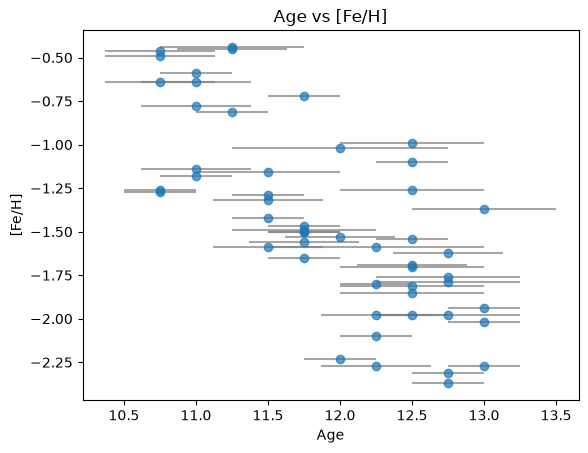

In [98]:
#Plot Age vs Mtlc
Age_df = merged_df.dropna(subset=['Age0', '[Fe/H]', '[Fe/H]'])
Age_df['[Fe/H]']= pd.to_numeric(Age_df['[Fe/H]'],errors='coerce')

plt.figure()
plt.errorbar(Age_df['Age0'], Age_df['[Fe/H]'], xerr=Age_e, marker='o', linestyle='', ecolor='gray', alpha=0.7)
plt.xlabel('Age')
plt.ylabel('[Fe/H]')
plt.title('Age vs [Fe/H]')


plt.show()

In [ ]:
#Plot Age vs R_gc with mtlc colour
plt.figure()
plt.scatter(Age_df['R_gc'], Age_df['Age0'], c=Age_df['[Fe/H]'], cmap='magma', vmin=Age_df['[Fe/H]'].min(), vmax=Age_df['[Fe/H]'].max())
plt.xlabel('R_gc')
plt.ylabel('Age')
plt.title('Radius vs Age colored by mtlc')
plt.colorbar(label='[Fe/H]')

plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

In [ ]:
#Plot mtlc vs R_gc with Age colour
plt.figure()
plt.scatter(Age_df['R_gc'], Age_df['[Fe/H]'], c=Age_df['Age0'], cmap='magma', vmin=Age_df['Age0'].min(), vmax=Age_df['Age0'].max())
plt.xlabel('R_gc')
plt.ylabel('[Fe/H]')
plt.title('Radius vs [Fe/H] colored by Age')
plt.colorbar(label='Age')

plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

In [ ]:
#Create 3d map of Clusters using astropy
Ra = merged_df['RA'].to_numpy(dtype=float)*u.rad
Dec = merged_df['DEC'].to_numpy(dtype=float)*u.rad
R_sun = merged_df['R_Sun'].to_numpy(dtype=float)*u.kpc
heli_coords = coord.SkyCoord(ra=Ra, dec=Dec, distance=R_sun, frame='icrs')
GC_coords = heli_coords.transform_to(coord.Galactocentric())
GC_cart = GC_coords.cartesian
GC_cart


In [ ]:
x_gc=GC_cart.x.value
y_gc=GC_cart.y.value
z_gc=GC_cart.z.value

x_gc_Sol=-coord.Galactocentric().galcen_distance
y_gc_Sol=0
z_gc_Sol=coord.Galactocentric().z_sun


#3d Map of Mtlc
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

#Plot sun on axes

sc=ax.scatter(x_gc, y_gc, z_gc, c=mtlc, s=10, marker='o', cmap='magma', vmin=mtlc.min(), vmax=mtlc.max())
# Sun Plot: ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
#ax.set_xlim(-20, 20)
#ax.set_ylim(-20, 20)
#ax.set_zlim(-20, 20)
plt.colorbar(sc, label='[Fe/H]')
plt.show()

In [ ]:
#3d Map of Velocity towards sun
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc=ax.scatter(x_gc, y_gc, z_gc, c=v_LSR, s=10, marker='o', cmap='magma', vmin=v_LSR.min(), vmax=v_LSR.max())
ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
#ax.set_xlim(-20, 20)
#ax.set_ylim(-20, 20)
#ax.set_zlim(-20, 20)
plt.colorbar(sc, label='Velocity towards Solar Neighbourhood')
plt.show()

In [ ]:
#3d Map of Mtlc
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

#Plot sun on axes

sc=ax.scatter(x_gc, y_gc, z_gc, c=log_tc, s=10, marker='o', cmap='magma', vmin=log_tc.min(), vmax=log_tc.max())
# Sun Plot: 
ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
# Galactic Center Plot: 
ax.scatter(0, 0, 0, c='red', s=200, marker='*', label='Galactic Center')
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)
plt.colorbar(sc, label='[Fe/H]')
plt.show()

In [ ]:
mask2 = mtlc <-0.8
mask1 = mtlc >=-0.8
plt.figure()
plt.scatter(R_gc[mask1], log_th[mask1], color='r', label='R_gc >= 10 kpc')
plt.scatter(R_gc[mask2], log_th[mask2], color='b', label='R_gc < 10 kpc')
plt.xlabel('')
plt.ylabel('')
plt.title('')

In [ ]:
plt.figure()
plt.scatter(R_gc, v_r, c=mtlc, cmap='magma')
plt.xlabel('')
plt.ylabel('')
plt.title('')

Text(0.5, 1.0, '')

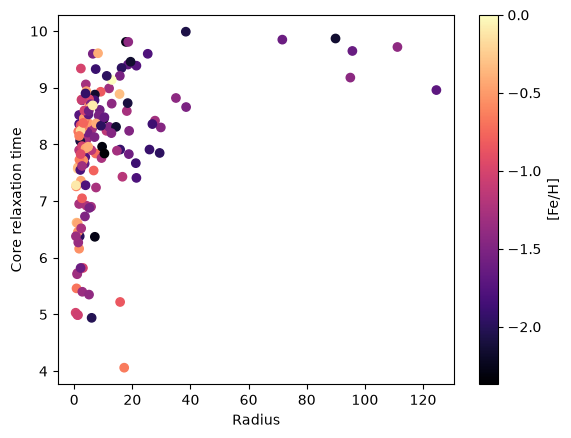

In [51]:
plt.figure()
plt.scatter(R_gc, log_tc, c=mtlc, cmap='magma')
plt.colorbar(label='[Fe/H]')
plt.xlabel('Radius')
plt.ylabel('Core relaxation time')
plt.title('')


In [55]:
R_Mask_60 = R_gc >= 60
df_filtered = merged_df[R_Mask_60]
df_filtered['ID']



6         AM 1
7     ERIDANUS
12    NGC 2419
17       PAL 3
19       PAL 4
45      PAL 14
Name: ID, dtype: str

In [77]:
harris_p2.iloc[-3]

ID        PAL 12
[Fe/H]     -0.85
wt             6
E(B-V)      0.02
V_HB       17.13
(m-M)V     16.46
V_t        11.99
M_V,t      -4.47
U-B         0.34
B-V         1.07
V-R             
V-I             
spt             
ellip           
Name: 154, dtype: object

np.float64(0.345)

np.float64(2.13)